# Convolution

> Part of *PHYS 0241: Biomedical Imaging* (Prof. Michael E. Durst, Middlebury College). The [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-05.html) shows the rendered version together with the pre-rendered animations (course password required).
>
> **Start here:** no setup is needed for this notebook. In Google Colab, choose **File > Save a copy in Drive** to keep your changes.
>
> *Provided for academic use in PHYS 0241; please do not repost or redistribute ([terms of use](https://github.com/durstme/textbook-biomedicalimaging-notebooks/blob/main/LICENSE.md)).*

## Import libraries

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import convolve
from skimage import data, util

In [2]:
%matplotlib inline
# Define global "bold" style parameters
# This restores the thicker lines and fonts seen in older versions
plot_params = {
    # --- Fonts ---
    'font.size': 18,
    'font.family': 'sans-serif',
    
    # --- Axes (The Box) ---
    'axes.linewidth': 1.0,       # Thicker box around the plot
    
    # --- Lines (The Signal) ---
    'lines.linewidth': 2.5,      # Thicker default plot lines
}

# Apply these settings globally
plt.rcParams.update(plot_params)

## Define parameters

In [3]:
# --- 1. Parameters ---
# Change this value to adjust the blur (formerly the slider)
psf_sigma = 5.0 

# --- 2. Load and Prepare Image ---
try:
    image_raw = data.moon()
except ImportError:
    image_raw = np.random.rand(256, 256)

# Convert to float (0.0 to 1.0)
image_raw = util.img_as_float(image_raw)
img_h, img_w = image_raw.shape

# --- 3. Create Gaussian Kernel (PSF) ---
# Calculate the kernel size based on sigma (usually 3 standard deviations)
radius = int(np.ceil(3 * psf_sigma))
x, y = np.mgrid[-radius:radius+1, -radius:radius+1]

# Gaussian formula
kernel = np.exp(-(x**2 + y**2) / (2 * psf_sigma**2)) # for a built-in function, use scipy.ndimage.gaussian_filter
# Normalize so the sum is 1 (preserves brightness)
kernel = kernel / kernel.sum()

# --- 4. Perform Convolution ---
# mode='reflect' handles the edges similarly to Mathematica's "Reversed" padding
convolved = convolve(image_raw, kernel, mode='reflect')

# --- 5. Prepare PSF Visualization ---
# To visualize the tiny kernel, we place it in the center of a black image
psf_display = np.zeros_like(image_raw)
kh, kw = kernel.shape

# Find center coordinates
start_y = (img_h - kh) // 2
start_x = (img_w - kw) // 2

# Place the kernel
psf_display[start_y:start_y+kh, start_x:start_x+kw] = kernel

# Normalize contrast for display (otherwise it looks pitch black)
if psf_display.max() > 0:
    psf_display = psf_display / psf_display.max()

## Plot

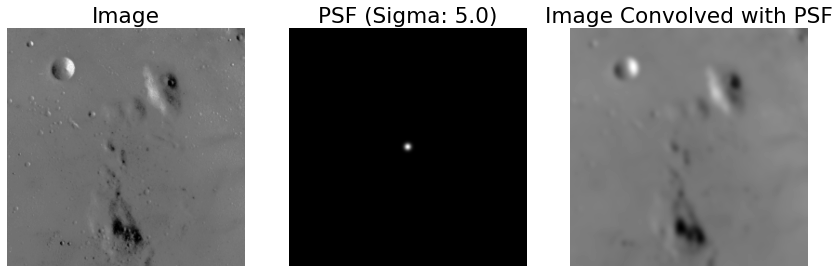

In [4]:
# --- 6. Plot Results ---
fig1, axes1 = plt.subplots(1, 3, figsize=(12, 4))

# Original Image
axes1[0].imshow(image_raw, cmap='gray')
axes1[0].set_title("Image")
axes1[0].axis('off')

# PSF Visualization
axes1[1].imshow(psf_display, cmap='gray', vmin=0, vmax=1)
axes1[1].set_title(f"PSF (Sigma: {psf_sigma})")
axes1[1].axis('off')

# Convolved Result
axes1[2].imshow(convolved, cmap='gray')
axes1[2].set_title("Image Convolved with PSF")
axes1[2].axis('off')

plt.tight_layout()
plt.show()

# Make interactive

In [ ]:
%matplotlib inline
import numpy as np
import matplotlib.pyplot as plt
from scipy.ndimage import gaussian_filter
from skimage import data, util
import ipywidgets as widgets
from IPython.display import display, clear_output

# --- 1. Global Style Settings ---
plt.rcParams.update({
    'font.size': 14,
    'font.family': 'sans-serif',
    'axes.linewidth': 1.0,
    'lines.linewidth': 2.5,
    'figure.autolayout': True, 
})

# --- 2. Load and Prepare Image ---
try:
    image_raw2 = data.moon()
except ImportError:
    # Fallback if skimage data isn't available
    image_raw2 = np.random.rand(256, 256)

image_raw2 = util.img_as_float(image_raw2)
img_h2, img_w2 = image_raw2.shape

# --- 3. Setup the Figure and Axes Once ---
# We create the figure objects *outside* the update loop to prevent flickering.
fig, axes = plt.subplots(1, 3, figsize=(12, 4))
fig.canvas.header_visible = False # Hides the header (if using widget backend)

# -- Left: Original Image --
axes[0].imshow(image_raw2, cmap='gray')
axes[0].set_title("Original Image")
axes[0].axis('off')

# -- Middle: PSF Visualization --
# Initialize with a placeholder
psf_placeholder = np.zeros((img_h2, img_w2))
im_psf = axes[1].imshow(psf_placeholder, cmap='gray', vmin=0, vmax=1)
axes[1].set_title("PSF Kernel")
axes[1].axis('off')

# -- Right: Convolved Result --
# Initialize with the raw image
im_result = axes[2].imshow(image_raw2, cmap='gray', vmin=0, vmax=1)
axes[2].set_title("Convolved Result")
axes[2].axis('off')

plt.close(fig) # Prevent double display of the static plot initially

# --- 4. Define the Update Logic ---
def update_plot(sigma):
    # A. Fast Convolution
    # gaussian_filter is significantly faster than standard convolution for large kernels
    if sigma < 0.1:
        convolved = image_raw2
    else:
        convolved = gaussian_filter(image_raw2, sigma=sigma, mode='reflect')
    
    # B. Generate PSF Display (Visual only)
    # We manually create a small kernel just to show the user what it looks like
    radius = int(np.ceil(3 * max(sigma, 1.0)))
    y, x = np.mgrid[-radius:radius+1, -radius:radius+1]
    kernel = np.exp(-(x**2 + y**2) / (2 * max(sigma, 0.1)**2))
    kernel = kernel / kernel.max() # Normalize max to 1 for visibility
    
    # Pad kernel to fit center of image for display
    psf_disp = np.zeros_like(image_raw2)
    ch, cw = psf_disp.shape
    kh, kw = kernel.shape
    start_y, start_x = (ch - kh)//2, (cw - kw)//2
    
    # Clip in case kernel exceeds image size (rare but possible with huge sigma)
    h_slice = slice(max(0, start_y), min(ch, start_y + kh))
    w_slice = slice(max(0, start_x), min(cw, start_x + kw))
    k_h_slice = slice(max(0, -start_y), min(kh, ch - start_y))
    k_w_slice = slice(max(0, -start_x), min(kw, cw - start_x))
    
    psf_disp[h_slice, w_slice] = kernel[k_h_slice, k_w_slice]
    
    # C. Update Data Handles (No full redraw)
    im_psf.set_data(psf_disp)
    im_result.set_data(convolved)
    
    # Update title dynamically
    axes[1].set_title(f"PSF ($\sigma={sigma:.1f}$ px)")
    
    # Handle display refresh
    if 'ipympl' in plt.get_backend():
        fig.canvas.draw_idle()
    else:
        clear_output(wait=True)
        display(fig)

# --- 5. Create Slider and Display ---
slider_sigma = widgets.FloatSlider(
    value=2.0,
    min=0.1,
    max=20.0,
    step=0.1,
    description='Blur Radius:',
    continuous_update=True, # Update while dragging
    layout=widgets.Layout(width='60%')
)

interactive_plot = widgets.interactive(update_plot, sigma=slider_sigma)
display(interactive_plot)

### Display animation with javascript from standalone html
[Link to animation](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-05_animation.html)

*Animation.* The pre-rendered animation for this section is shown on the [textbook page for this notebook](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/python/ch05/ch05-05.html) (direct link: [ch05-05_animation.html](https://durstlab.middcreate.net/teaching/protected/textbook-biomedicalimaging/animations/ch05/ch05-05_animation.html)). It is not embedded here because Colab cannot load files from the textbook site; running the code above produces the live version.